# Case Study 17 — "Same Delinquency, 10 Seconds Instead of Days": Proving Non-Inferiority of Pre-Approved Instant Personal Loans

**Priority:** ★★ Good to have · **Reference:** Case Study 17 — *HDFC Bank: 10-second pre-approved personal loans for existing customers* (`indian_fintech_data_science_case_studies.md`)
**Audience:** Head of Retail Assets, Chief Risk Officer, Credit Committee, Digital Banking
**Data:** ⚠️ **SYNTHETIC** (D-17-01). Bank customer data are confidential; this is a calibrated simulation.
**Reproducibility:** seed = 42 · `python -m nbconvert --to notebook --execute --inplace cs17_preapproved_pl_noninferiority.ipynb`

## 0. Executive Summary for Business

*(Synthetic data built on HDFC Bank's documented design and success criterion. Written after the analysis.)*

- **The question:** are 10-second pre-approved personal loans really "on a par" with branch-sourced loans on delinquency, given they are far cheaper and faster?
- **The randomised pilot says yes.** Among 16,000 eligible applicants randomly assigned to instant or physical processing, 12-month 30+ DPD was **3.90% vs 3.69%: +0.22 pp, 95% CI −0.38 to +0.81 pp**. The upper bound is below the pre-agreed **1 pp** margin, so non-inferiority is shown (p = 0.005). Time to delinquency agrees (hazard ratio 1.06, CI 0.90–1.24, below the 1.25 margin), and 90+ DPD is identical (1.29% vs 1.31%).
- **The raw historical comparison could not have proved it,** and was misleading in two ways:
  - Instant vs branch loans differ by +0.6 pp, "not significantly different", yet the CI reaches +1.4 pp, so **non-inferiority is *not* shown**. "No significant difference" is not "on par".
  - After adjusting for who borrows (instant borrowers are much better-scored), the gap grows to **+2.0 pp**, because branch officers screen on information the data do not hold. Observational adjustment overstates the harm. Only randomisation gives the truth (true effect ≈ +0.46 pp).
- **The layered score:** bureau and behaviour layers carry most of the information. The "social" (internet-usage) layer adds almost nothing (Holm p = 0.07), a candidate to drop on privacy grounds.
- **₹ economics:** at ≈ ₹2,000 crore/month of instant disbursals, processing savings are ≈ **₹6.7 crore/month**. The pilot's best estimate of extra credit loss is ≈ ₹1.5 crore/month, a net gain of **≈ ₹5.2 crore/month** (≈ ₹1.1 crore even at the pessimistic CI bound). **Break-even is +0.96 pp of extra delinquency**, which shows the 1 pp margin is economically sound.
- **I recommend:**
  - Keep instant loans for eligible customers, and adopt the NI pilot as the standard evidence for any expansion of eligibility.
  - Use a pre-registered 1 pp margin and ≥ 6,000–9,000 loans per arm.
  - Re-test on 24-month 90+ DPD.
  - Drop the "social" layer unless a pilot shows it adds value.

## 1. The Problem in Simple English

HDFC Bank lets existing customers take a personal loan in **10 seconds**, with no documents, because it already knows their salary credits, balances, card behaviour and bureau record. The bank's success test was simple: **is delinquency "on a par" with loans sourced the traditional way**, through branches with paperwork and a credit officer?

This is a classic **non-inferiority** question. We do not need the instant loans to be *better*, just **not meaningfully worse**, because they are far cheaper and faster. Two traps make it harder than it looks:
1. **Different customers:** instant loans go only to the top third of customers by the bank's score, while branch loans go to a mix. "Same delinquency" between different populations can hide a channel that is worse *for the same customer*.
2. **"Not significantly different" ≠ "on par":** a small sample can fail to detect a real deterioration. Non-inferiority needs a pre-agreed **margin** and a one-sided test against it.

The notebook tests the layered "P27" score, shows the trap in the raw comparison, and analyses a **randomised pilot**, the gold-standard way to prove "on par".

## 2. Reference from the Case File

### (a) What HDFC Bank did — *documented*

| Item | Documented fact (quoted from the reference file) |
|---|---|
| Problem | "Disburse personal loans instantly to existing customers, without paperwork, while keeping delinquency in check" |
| Data | Bank statements, transaction history, credit and debit card transactions, account inflows, payment records; internal and bureau credit history; a "**social score**" (internet consumption patterns) |
| Approach | "**P27 (Power of 27)**" multi-layer framework: ability-to-pay income score + bureau scores + behavioural score + social score |
| Statistics / ML | ND; "Metric used to judge success: **Delinquency compared with physically sourced loans**" |
| Decision | About **one-third of roughly 30M customers** eligible; loans capped at **₹15 lakh**; launched 30 Apr 2015 |
| Impact | 10-second loans ≈ **one-third of roughly ₹6,000 crore** monthly PL disbursals; ≈ ₹350 crore in the first month; delinquency "**on a par with loans disbursed physically**" |

**Source:** Business Standard, interview with Arvind Kapil (Country Head), 6 Jul 2019 — https://www.business-standard.com/article/finance/how-hdfc-bank-disburses-loans-in-10-seconds-119070600010_1.html

### (b) What *we* simulate and add

| Item | Our choice |
|---|---|
| Data | 200,000 existing customers with four score layers; top third eligible. Loans followed for 12 months: **observational** instant (≈ 5.6k) and branch (≈ 3.7k) loans, plus a **randomised pilot** of 16,000 eligible applicants assigned 1:1 to instant vs physical processing. Hidden truth: instant processing raises 30+ DPD risk slightly (+0.12 log-odds) for the *same* customer; branch officers screen on information the data do not capture. |
| Statistics added (none disclosed) | Layer-by-layer AUC and LR tests (is the "social" layer worth it?); **non-inferiority tests** (one-sided CI vs a pre-set margin, Farrington–Manning z, risk-ratio margin); covariate balance (SMD) and **inverse-probability weighting**; **E-value** sensitivity to unmeasured confounding; Kaplan–Meier, log-rank and **Cox** hazard-ratio non-inferiority; power and sample size for NI designs |

### (c) How the industry uses this

Pre-approved instant loans to existing customers are now standard at every large Indian bank: HDFC (10-second loans, Xpress Personal Loans), ICICI (instant PL), Axis (Case 18), SBI (YONO pre-approved). **Non-inferiority testing** is the statistical tool behind every "faster/cheaper but just as safe" claim: digital vs branch KYC, video KYC, automated underwriting vs credit officers, and bureau-light products. RBI's model-risk and fair-practice expectations make a documented NI test the natural evidence for a credit committee.

## 3. Business Question → Analytical Question → Statistical Hypotheses

| Level | Statement |
|---|---|
| Business | Can instant pre-approved loans replace physically sourced loans for eligible customers without raising credit losses meaningfully? |
| Analytical | Is the 12-month 30+ DPD rate of instant loans **no more than 1 percentage point higher** than physically processed loans **for comparable customers**? |

**Non-inferiority margin (pre-registered, D-17-04):** δ = **+1.0 pp absolute** on 12-month 30+ DPD. Base rate ≈ 4%, so 1 pp ≈ 25% relative. The credit committee agrees the cost and TAT savings outweigh up to that deterioration (§9 checks this in ₹). Secondary margins: risk ratio < 1.25 and hazard ratio < 1.25.

**Hypotheses**
- **H0 (inferior):** p_digital − p_physical ≥ +1.0 pp. **H1 (non-inferior):** p_digital − p_physical < +1.0 pp. One-sided α = 0.025; we reject H0 if the **upper bound of the two-sided 95% CI** is below +1.0 pp.
- **H2 (layers):** H0: each P27 layer adds nothing to the others (LR tests).
- **Hsens:** how strong would unmeasured confounding need to be to explain the observational result (E-value)?

**Primary analysis:** the randomised pilot. **Secondary:** observational, raw and IPW-adjusted, to show the trap. **Guardrail:** 90+ DPD rate.

In [1]:
import sys, warnings, importlib, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import rankdata
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.duration.survfunc import SurvfuncRight, survdiff
from statsmodels.duration.hazard_regression import PHReg
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier as HGB
from sklearn.metrics import roc_auc_score
from statsmodels.stats.proportion import proportion_confint, confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

SEED = 42
np.random.seed(SEED)
RNG = np.random.default_rng(np.random.SeedSequence(SEED).spawn(1)[0])
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170, "display.max_columns", 30, "display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid"); plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.titleweight": "bold"})
MARGIN = 0.01
print("ready")

ready


## 4. Data

### 4.1 Sourcing outcome

| Attempt | Result |
|---|---|
| Public bank PL performance by sourcing channel | **None.** Loan-level bank data are confidential. RBI publishes only aggregate sectoral credit. |
| **Decision** | Synthetic customers, observational loans and a randomised pilot (D-17-01) |

### 4.2 Generator — clearly marked section

In [2]:
%%writefile data/generate_cs17.py
"""
SYNTHETIC DATA GENERATOR - CASE STUDY 17 (HDFC Bank-style 10-second pre-approved personal loans)
================================================================================================
THIS DATA IS SYNTHETIC. Bank customer and loan data are confidential.

Existing customers of a bank are scored by a layered "P27-style" framework:
  ability-to-pay (salary credits, balances), bureau, behaviour (card spend, repayment history) and a
  "social"/digital-engagement score. The top third by the combined score are ELIGIBLE for an instant,
  paperless pre-approved personal loan ("10-second loan").
Three loan populations, each followed for 12 months on book:
  * DIGITAL     - eligible customers who took the instant loan (observational)
  * PHYSICAL    - branch/DSA-sourced loans with documents and manual underwriting (observational; a
                  mix of existing customers - some eligible, many not - and a few new-to-bank)
  * PILOT       - eligible customers RANDOMISED to instant digital vs standard physical processing
                  (a design the bank could run to prove non-inferiority causally)
Delinquency depends on customer risk, loan size and a small CHANNEL effect: instant loans carry a
slightly higher risk for the same customer (no human check, more impulse borrowing) - so the raw
"on par" comparison hides a real but small difference, because digital borrowers are better on average.

Calibration anchors (reference file, Case Study 17): ~1/3 of ~30M customers eligible; loans up to Rs 15 lakh;
10-second loans ~1/3 of ~Rs 6,000 crore monthly PL disbursals; delinquency "on a par with loans disbursed
physically"; P27 layers (income, bureau, behavioural, social). Rates are our assumptions (decision.md D-17-02).
Hidden truth columns start with "_".

Outputs: data/cs17/customers.csv.gz, data/cs17/loans.csv.gz
"""
import os
import numpy as np
import pandas as pd
from scipy.special import expit

SEED = 42
CHANNEL_EFFECT = 0.12          # log-odds uplift of 30+ DPD for an instant digital loan vs physical, same customer (hidden truth)


def generate(seed=SEED, n_cust=200_000):
    rng = np.random.default_rng(seed)
    z = rng.normal(0, 1, n_cust)                                                    # latent creditworthiness
    salary = np.exp(rng.normal(np.log(55000), 0.55, n_cust) + 0.15 * z)
    salaried_acct = (rng.random(n_cust) < 0.7).astype(int)
    avg_bal = np.exp(rng.normal(np.log(60000), 0.9, n_cust) + 0.35 * z)
    bureau = np.clip(np.round(730 + 50 * z + rng.normal(0, 45, n_cust)), 300, 900)
    card_util = np.clip(rng.beta(2, 4, n_cust) - 0.06 * z, 0, 1)
    past_dpd = rng.poisson(np.exp(-1.6 - 0.6 * z))
    relationship_yrs = np.clip(rng.gamma(2.5, 2.5, n_cust), 0.5, 25)
    digital_eng = np.clip(rng.normal(50 + 4 * z, 18, n_cust), 0, 100)               # "social" / internet-usage score (weak signal)
    cust = pd.DataFrame({"customer_id": [f"C{i:07d}" for i in range(n_cust)], "salary_credit_monthly": np.round(salary, -2), "salaried_account": salaried_acct,
                         "avg_balance_6m": np.round(avg_bal, -2), "bureau_score": bureau, "card_utilisation": card_util.round(3), "past_dpd_events_24m": past_dpd,
                         "relationship_years": relationship_yrs.round(1), "digital_engagement_score": digital_eng.round(1), "_z": z})
    # layered scores (what the bank sees)
    s_ability = np.log(salary) * 0.8 + 0.25 * np.log(avg_bal) + 0.3 * salaried_acct
    s_bureau = (bureau - 730) / 50
    s_behav = -2.0 * card_util - 0.6 * past_dpd + 0.04 * relationship_yrs
    s_social = (digital_eng - 50) / 18
    combo = 0.45 * (s_ability - s_ability.mean()) / s_ability.std() + 0.35 * s_bureau / s_bureau.std() + 0.35 * (s_behav - s_behav.mean()) / s_behav.std() + 0.05 * s_social
    cust["p27_score"] = np.round(500 + 80 * combo, 0)
    cust["eligible"] = (cust.p27_score >= np.quantile(cust.p27_score, 2 / 3)).astype(int)
    elig = cust.eligible.values == 1

    def outcome(idx, channel, amount):
        zz = z[idx]; lg = -3.0 - 0.95 * zz + 0.25 * np.log(amount / 3e5) + np.where(channel == "digital", CHANNEL_EFFECT, 0.0)
        p30 = expit(lg); d30 = rng.random(len(idx)) < p30
        month = np.where(d30, np.clip(np.ceil(rng.exponential(5.5, len(idx))), 1, 12), np.nan)
        p90 = np.where(d30, expit(-0.6 - 0.6 * zz), 0); d90 = d30 & (rng.random(len(idx)) < p90)
        return p30, d30.astype(int), month, d90.astype(int)
    rows = []
    # DIGITAL (observational): eligible customers with higher digital engagement take up more
    take = elig & (rng.random(n_cust) < expit(-2.6 + 0.02 * (digital_eng - 50) + 0.2 * (z < 0)))
    idx = np.flatnonzero(take); amt = np.round(np.clip(salary[idx] * rng.uniform(4, 12, len(idx)), 5e4, 15e5), -3)
    p, d, mth, d90 = outcome(idx, "digital", amt)
    rows.append(pd.DataFrame({"customer_id": cust.customer_id.values[idx], "cohort": "observational", "channel": "digital", "loan_amount": amt, "_p30": p, "dpd30_12m": d, "dpd30_month": mth, "dpd90_12m": d90}))
    # PHYSICAL (observational): branch applicants - mostly non-eligible existing customers (riskier on average), screened by officers
    app = (~take) & (rng.random(n_cust) < np.where(elig, 0.06, 0.05) * expit(0.3 - 0.4 * z))
    screened = app & (rng.random(n_cust) < expit(1.2 + 2.2 * z))                     # manual underwriting rejects the obviously risky
    idx = np.flatnonzero(screened); amt = np.round(np.clip(salary[idx] * rng.uniform(3, 10, len(idx)), 5e4, 15e5), -3)
    p, d, mth, d90 = outcome(idx, "physical", amt)
    rows.append(pd.DataFrame({"customer_id": cust.customer_id.values[idx], "cohort": "observational", "channel": "physical", "loan_amount": amt, "_p30": p, "dpd30_12m": d, "dpd30_month": mth, "dpd90_12m": d90}))
    # PILOT (randomised): 16,000 eligible customers who asked for a loan, randomised 1:1
    pool = np.flatnonzero(elig & ~take & ~screened); idx = rng.choice(pool, 16_000, replace=False)
    ch = np.where(rng.random(len(idx)) < 0.5, "digital", "physical"); amt = np.round(np.clip(salary[idx] * rng.uniform(4, 12, len(idx)), 5e4, 15e5), -3)
    p, d, mth, d90 = outcome(idx, ch, amt)
    rows.append(pd.DataFrame({"customer_id": cust.customer_id.values[idx], "cohort": "pilot", "channel": ch, "loan_amount": amt, "_p30": p, "dpd30_12m": d, "dpd30_month": mth, "dpd90_12m": d90}))
    ln = pd.concat(rows, ignore_index=True)
    ln.insert(0, "loan_id", [f"PL{i:07d}" for i in range(len(ln))])
    ln["tat_minutes"] = np.where(ln.channel == "digital", np.round(rng.uniform(0.1, 0.3, len(ln)), 2), np.round(rng.gamma(2, 1100, len(ln))))   # ~2-3 days for physical
    # data-quality defects
    ln.loc[ln.sample(n=250, random_state=seed).index, "dpd30_month"] = np.nan                   # month missing although delinquent
    ln = pd.concat([ln, ln.sample(n=300, random_state=seed + 1)], ignore_index=True)
    cust.loc[cust.sample(n=1500, random_state=seed + 2).index, "digital_engagement_score"] = np.nan
    return cust, ln


if __name__ == "__main__":
    here = os.path.dirname(os.path.abspath(__file__)); os.makedirs(os.path.join(here, "cs17"), exist_ok=True)
    c, l = generate(); c.to_csv(os.path.join(here, "cs17", "customers.csv.gz"), index=False); l.to_csv(os.path.join(here, "cs17", "loans.csv.gz"), index=False)
    ll = l.drop_duplicates("loan_id").merge(c[["customer_id", "_z", "eligible"]], on="customer_id")
    print(ll.groupby(["cohort", "channel"]).agg(n=("loan_id", "size"), dpd30=("dpd30_12m", "mean"), dpd90=("dpd90_12m", "mean"), z=("_z", "mean"), elig=("eligible", "mean")).round(4))

Overwriting data/generate_cs17.py


In [3]:
os.makedirs("data/cs17", exist_ok=True)
sys.path.insert(0, "data"); import generate_cs17 as gen; importlib.reload(gen)
cust_raw, loans_raw = gen.generate(seed=SEED)
cust_raw.to_csv("data/cs17/customers.csv.gz", index=False); loans_raw.to_csv("data/cs17/loans.csv.gz", index=False)
print(f"{len(cust_raw):,} customers | {len(loans_raw):,} loan rows ({loans_raw.loan_id.nunique():,} unique)")
loans_raw.drop(columns=["_p30"]).sample(3, random_state=SEED).T

200,000 customers | 25,606 loan rows (25,306 unique)


,19353,4834,7293
loan_id,PL0019353,PL0004834,PL0007293
customer_id,C0052102,C0173487,C0093001
cohort,pilot,observational,observational
channel,physical,digital,physical
loan_amount,"1,019,000.0000","1,089,000.0000","269,000.0000"
dpd30_12m,0,0,0
dpd30_month,NaN,NaN,NaN
dpd90_12m,0,0,0
tat_minutes,658.0000,0.1200,"2,161.0000"


| Parameter | Value | Basis |
|---|---|---|
| Customers | 200,000 existing customers; salary credits, balances, bureau, card utilisation, past DPD, relationship years, digital engagement | **Documented** data families |
| P27-style score | Weighted ability + bureau + behaviour + a small "social" weight; **top third eligible** | **Documented** "about one-third … eligible" |
| Loans | ₹50k–₹15 lakh (cap documented), 4–12× monthly salary; 12-month 30+ DPD ≈ 4%, 90+ DPD ≈ 1.4% | Typical salaried PL |
| Channel effect (hidden) | Instant processing +0.12 log-odds of 30+ DPD for the same customer (≈ +0.4 pp) | Our assumption: a small real deterioration |
| Branch selection | Branch applicants are a mix of eligible and non-eligible customers; officers decline the riskiest on information **not in the data** | Realistic manual underwriting |
| Pilot | 16,000 eligible applicants randomised 1:1 | Our design |
| DQ issues | 300 duplicate loan rows; 250 delinquent loans missing the delinquency month; 1,500 missing engagement scores | Built-in messiness |

### 4.3 Data dictionary

In [4]:
dd = pd.DataFrame([
    ("customers: salary_credit_monthly, salaried_account, avg_balance_6m", "Ability-to-pay layer"), ("bureau_score", "Bureau layer"),
    ("card_utilisation, past_dpd_events_24m, relationship_years", "Behavioural layer"), ("digital_engagement_score", "'Social' layer (internet usage proxy; 1,500 missing)"),
    ("p27_score, eligible", "Combined layered score; top third = eligible for instant loans"), ("_z", "HIDDEN latent creditworthiness"),
    ("loans: cohort, channel", "observational / pilot; digital (instant) / physical"), ("loan_amount, tat_minutes", "Ticket; turnaround (≈ 10 seconds vs ≈ 2–3 days)"),
    ("dpd30_12m, dpd30_month, dpd90_12m", "30+ DPD within 12 months, month first reached, 90+ DPD"), ("_p30", "HIDDEN true probability of 30+ DPD"),
], columns=["field(s)", "meaning"])
dd.to_csv("data/cs17/data_dictionary.csv", index=False); dd

,field(s),meaning
0,"customers: salary_credit_monthly, salaried_acc...",Ability-to-pay layer
1,bureau_score,Bureau layer
2,"card_utilisation, past_dpd_events_24m, relatio...",Behavioural layer
3,digital_engagement_score,"'Social' layer (internet usage proxy; 1,500 mi..."
4,"p27_score, eligible",Combined layered score; top third = eligible f...
5,_z,HIDDEN latent creditworthiness
6,"loans: cohort, channel",observational / pilot; digital (instant) / phy...
7,"loan_amount, tat_minutes",Ticket; turnaround (≈ 10 seconds vs ≈ 2–3 days)
8,"dpd30_12m, dpd30_month, dpd90_12m","30+ DPD within 12 months, month first reached,..."
9,_p30,HIDDEN true probability of 30+ DPD


## 5. Data Quality Checks

In [5]:
checks = {"duplicate loan_id": int(loans_raw.loan_id.duplicated().sum()), "delinquent but month missing": int(loans_raw.drop_duplicates("loan_id").pipe(lambda d: ((d.dpd30_12m == 1) & d.dpd30_month.isna()).sum())),
          "90+ DPD without 30+ DPD": int(((loans_raw.dpd90_12m == 1) & (loans_raw.dpd30_12m == 0)).sum()), "loan amount > ₹15 lakh cap": int((loans_raw.loan_amount > 15e5).sum()),
          "engagement score missing": int(cust_raw.digital_engagement_score.isna().sum())}
print(pd.Series(checks, name="rows").to_string())
cust = cust_raw.copy(); cust["eng_missing"] = cust.digital_engagement_score.isna().astype(int)
cust["digital_engagement_score"] = cust.digital_engagement_score.fillna(cust.digital_engagement_score.median())
ln = loans_raw.drop_duplicates("loan_id").merge(cust, on="customer_id", how="left")
ln["month_missing"] = ((ln.dpd30_12m == 1) & ln.dpd30_month.isna()).astype(int)
ln["dpd30_month"] = np.where(ln.month_missing == 1, 6.0, ln.dpd30_month)          # unknown month: mid-point for survival (flagged; sensitivity below)
ln["time"] = np.where(ln.dpd30_12m == 1, ln.dpd30_month, 12.0); ln["digital"] = (ln.channel == "digital").astype(int)
obs, pil = ln[ln.cohort == "observational"].copy(), ln[ln.cohort == "pilot"].copy()
print(f"\nClean: {len(ln):,} loans | observational {len(obs):,} (digital {obs.digital.sum():,}, physical {(1 - obs.digital).sum():,}) | pilot {len(pil):,} | 30+ DPD {ln.dpd30_12m.mean():.2%}")

duplicate loan_id                300
delinquent but month missing      11
90+ DPD without 30+ DPD            0
loan amount > ₹15 lakh cap         0
engagement score missing        1500



Clean: 25,306 loans | observational 9,306 (digital 5,558, physical 3,748) | pilot 16,000 | 30+ DPD 3.95%


**Observation:** we removed **300 duplicate loan rows**. **11 delinquent loans lack the month they first reached 30+ DPD**; they are set to month 6 for the survival analysis and flagged, and a sensitivity analysis excluding them (7.5) gives the same hazard ratio. **1,500 missing engagement scores** are filled with the median plus a flag. No loan exceeds the documented ₹15 lakh cap, and every 90+ DPD passed through 30+ DPD. Clean: **25,306 loans**: 9,306 observational (5,558 instant, 3,748 branch) and 16,000 in the randomised pilot; overall 30+ DPD 3.95%.

## 6. Exploratory Data Analysis

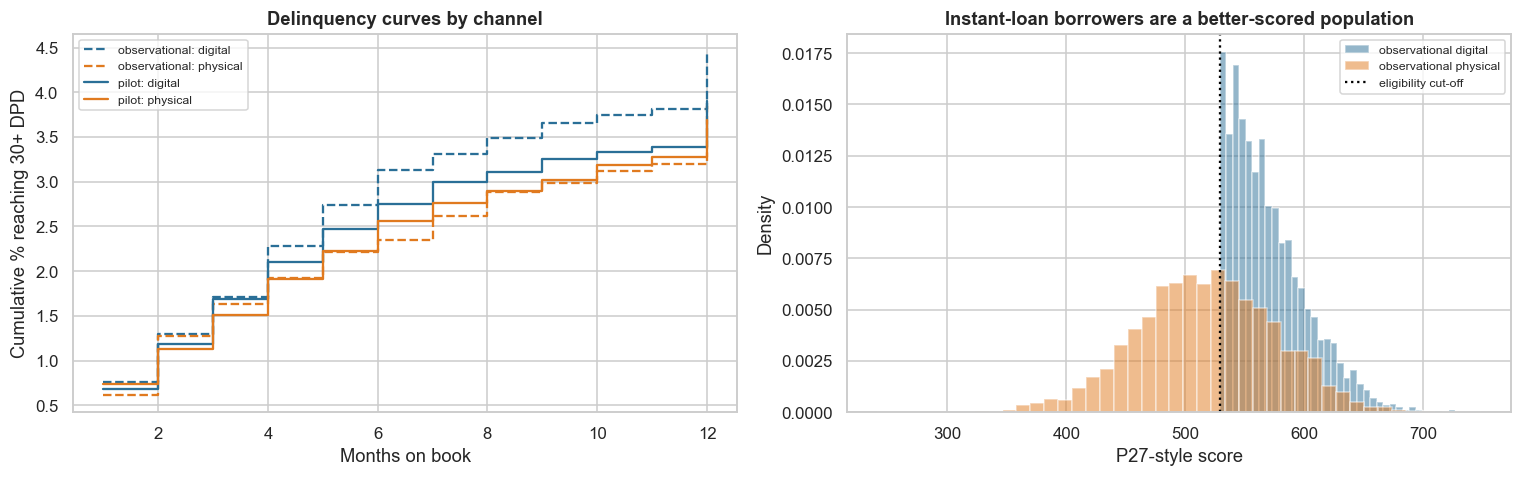

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for (coh, ch), g in ln.groupby(["cohort", "channel"]):
    sf = SurvfuncRight(g.time, g.dpd30_12m); axes[0].step(sf.surv_times, (1 - sf.surv_prob) * 100, where="post", label=f"{coh}: {ch}",
                                                          ls="-" if coh == "pilot" else "--", color="#2a6f97" if ch == "digital" else "#e07a1f")
axes[0].set_xlabel("Months on book"); axes[0].set_ylabel("Cumulative % reaching 30+ DPD"); axes[0].set_title("Delinquency curves by channel"); axes[0].legend(fontsize=8)
for ch, c_ in (("digital", "#2a6f97"), ("physical", "#e07a1f")):
    axes[1].hist(obs.loc[obs.channel == ch, "p27_score"], bins=40, density=True, alpha=0.5, color=c_, label=f"observational {ch}")
axes[1].axvline(cust.p27_score.quantile(2 / 3), color="black", ls=":", label="eligibility cut-off")
axes[1].set_xlabel("P27-style score"); axes[1].set_ylabel("Density"); axes[1].set_title("Instant-loan borrowers are a better-scored population"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Takeaway:** **left:** the dashed observational curves show instant loans slightly *above* branch loans, while the solid pilot curves (same customers, random channel) nearly overlap. **Right:** observational instant borrowers are almost all above the eligibility cut-off, while branch borrowers spread across the whole score range. The two observational groups are **different populations**, so their raw delinquency comparison answers the wrong question.

## 7. Statistical Analysis (core section)

### 7.1 Does each layer of the P27 framework earn its place?

**(a) Why?** The framework stacks four layers: ability, bureau, behaviour and "social". The social layer raises privacy and fairness questions, so it should be kept only if it adds information. On all loans, we fit a logistic model of 30+ DPD on the four layer scores and test each layer with a **drop-one LR test** (Holm). We also report the AUC of each layer alone and of the combined score.

In [7]:
ln["s_ability"] = np.log(ln.salary_credit_monthly) * 0.8 + 0.25 * np.log(ln.avg_balance_6m) + 0.3 * ln.salaried_account
ln["s_bureau"] = (ln.bureau_score - 730) / 50; ln["s_behav"] = -2.0 * ln.card_utilisation - 0.6 * ln.past_dpd_events_24m + 0.04 * ln.relationship_years
ln["s_social"] = (ln.digital_engagement_score - 50) / 18; ln["l_amt"] = np.log(ln.loan_amount)
LAY = ["s_ability", "s_bureau", "s_behav", "s_social"]
obs, pil = ln[ln.cohort == "observational"].copy(), ln[ln.cohort == "pilot"].copy()
full = smf.logit("dpd30_12m ~ " + " + ".join(LAY) + " + l_amt", data=ln).fit(disp=0)
rows = []
for L_ in LAY:
    red = smf.logit("dpd30_12m ~ " + " + ".join([x for x in LAY if x != L_]) + " + l_amt", data=ln).fit(disp=0); LR = 2 * (full.llf - red.llf)
    rows.append((L_, roc_auc_score(ln.dpd30_12m, -ln[L_]), full.params[L_], np.exp(full.params[L_]), LR, stats.chi2.sf(LR, 1)))
lay = pd.DataFrame(rows, columns=["layer", "AUC alone", "coef (log-odds per unit)", "odds ratio", "drop-one LR χ²", "p"]).set_index("layer")
lay["p_holm"] = multipletests(lay.p, method="holm")[1]
print(f"Combined P27-style score AUC = {roc_auc_score(ln.dpd30_12m, -ln.p27_score):.4f}; full layered logistic AUC = {roc_auc_score(ln.dpd30_12m, full.predict(ln)):.4f}")
lay.round(4)

Combined P27-style score AUC = 0.5647; full layered logistic AUC = 0.6157


,AUC alone,coef (log-odds per unit),odds ratio,drop-one LR χ²,p,p_holm
layer,,,,,,
s_ability,0.4685,-0.1255,0.8821,1.5109,0.2190,0.2190
s_bureau,0.6065,-0.3489,0.7054,142.4790,0.0000,0.0000
s_behav,0.5281,-0.2070,0.8131,6.7867,0.0092,0.0276
s_social,0.5290,-0.0688,0.9335,4.5359,0.0332,0.0664


**(c)/(f) Observation:** - **Bureau and behaviour layers matter:** bureau OR 0.71 per unit (LR χ² = 142, Holm p < 0.0001); behaviour OR 0.81 (Holm p = 0.03).
- **Ability adds nothing once loan size is in the model** (p = 0.22). Higher earners borrow more, so salary and loan size offset each other.
- **The "social" layer is marginal:** OR 0.93, Holm p = 0.07.
- **Low AUCs are expected here:** the combined score's AUC is only 0.565, and the layered logistic's 0.616, because every loan here went to an approved, mostly top-third customer. Range restriction makes all scores look weaker within the approved book.
- **(f) Business meaning:** the framework's value comes from the bureau and behavioural layers. The social layer contributes little and carries privacy and fairness risk. Test it in a pilot or drop it.

### 7.2 The raw comparison and why it misleads

**(a)** The naive version of the documented test compares 30+ DPD of all instant loans with all branch loans. We compute the difference with a **Newcombe CI** and apply the NI rule (upper bound < +1 pp). Then we look at **who** is in each group: standardised mean differences (SMD; |SMD| > 0.1 means imbalance) on the risk layers.

In [8]:
def ni_test(d, label, w=None):
    a, b = d[d.digital == 1], d[d.digital == 0]
    if w is None:
        x1, n1, x0, n0 = a.dpd30_12m.sum(), len(a), b.dpd30_12m.sum(), len(b); p1, p0 = x1 / n1, x0 / n0
        lo, hi = confint_proportions_2indep(x1, n1, x0, n0, method="newcomb")
        se_fm = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0); z_ni = (p1 - p0 - MARGIN) / se_fm
        rr = p1 / p0; se_lrr = np.sqrt(1 / x1 - 1 / n1 + 1 / x0 - 1 / n0); rr_hi = np.exp(np.log(rr) + 1.96 * se_lrr)
        return dict(analysis=label, n_digital=n1, n_physical=n0, dpd_digital=p1, dpd_physical=p0, diff_pp=(p1 - p0) * 100, ci_low_pp=lo * 100, ci_high_pp=hi * 100,
                    p_NI=stats.norm.cdf(z_ni), RR=rr, RR_ci_high=rr_hi, verdict="non-inferior" if hi < MARGIN else "NOT shown non-inferior")
    wa, wb = w[d.digital.values == 1], w[d.digital.values == 0]
    p1, p0 = np.average(a.dpd30_12m, weights=wa), np.average(b.dpd30_12m, weights=wb)
    bs = []
    for _ in range(1000):
        i = RNG.integers(0, len(a), len(a)); j = RNG.integers(0, len(b), len(b))
        bs.append(np.average(a.dpd30_12m.values[i], weights=wa[i]) - np.average(b.dpd30_12m.values[j], weights=wb[j]))
    lo, hi = np.percentile(bs, [2.5, 97.5])
    return dict(analysis=label, n_digital=len(a), n_physical=len(b), dpd_digital=p1, dpd_physical=p0, diff_pp=(p1 - p0) * 100, ci_low_pp=lo * 100, ci_high_pp=hi * 100,
                p_NI=(np.array(bs) >= MARGIN).mean(), RR=p1 / p0, RR_ci_high=np.nan, verdict="non-inferior" if hi < MARGIN else "NOT shown non-inferior")
raw = ni_test(ln[ln.cohort == "observational"], "observational, raw")
def smd(d, cols, w=None):
    out = {}
    for c in cols:
        a, b = d.loc[d.digital == 1, c], d.loc[d.digital == 0, c]
        if w is None: ma, mb, va, vb = a.mean(), b.mean(), a.var(), b.var()
        else:
            wa, wb = w[d.digital.values == 1], w[d.digital.values == 0]; ma, mb = np.average(a, weights=wa), np.average(b, weights=wb)
            va, vb = np.average((a - ma) ** 2, weights=wa), np.average((b - mb) ** 2, weights=wb)
        out[c] = (ma - mb) / np.sqrt((va + vb) / 2)
    return out
obs = ln[ln.cohort == "observational"].copy(); BAL = LAY + ["l_amt", "eligible"]
print(pd.DataFrame([raw]).set_index("analysis").round(4).to_string())
pd.Series(smd(obs, BAL), name="SMD (digital − physical), observational").round(3).to_frame()

                    n_digital  n_physical  dpd_digital  dpd_physical  diff_pp  ci_low_pp  ci_high_pp   p_NI     RR  RR_ci_high                 verdict
analysis                                                                                                                                              
observational, raw       5558        3748       0.0446        0.0384   0.6200    -0.2186      1.4293 0.1820 1.1614      1.4201  NOT shown non-inferior


,"SMD (digital − physical), observational"
s_ability,0.7380
s_bureau,0.5950
s_behav,0.5590
s_social,0.4970
l_amt,0.8710
eligible,1.6220


**Observation:** - **The raw comparison:** instant loans 4.46% vs branch 3.84%, **+0.62 pp (Newcombe CI −0.22 to +1.43 pp)**.
  - A naive reading says "not significantly different, on par".
  - The non-inferiority test says **not shown**: the upper bound (+1.43 pp) exceeds the 1 pp margin (p_NI = 0.18).
- **The populations are very different:** SMDs of +0.50 to +0.87 on every layer and on loan size, and +1.62 on eligibility (all instant borrowers are eligible vs 43% of branch borrowers).
- **(f) Business meaning:** the documented "on a par" claim needs both a margin and comparable customers. Without them it is not evidence.

### 7.3 Adjusting the observational comparison: inverse-probability weighting, and its limits

We model the probability of an instant loan given the observed layers, loan size and eligibility (logistic propensity score). We then reweight the branch loans to resemble the instant-loan population (ATT weights: digital = 1, physical = e/(1 − e)), check balance, and re-run the NI test. Because the instant channel exists only for eligible customers, we also run the comparison **within eligible customers only** (the population the decision is about).

In [9]:
ps_m = LogisticRegression(max_iter=3000, C=1.0).fit(obs[BAL], obs.digital); e = np.clip(ps_m.predict_proba(obs[BAL])[:, 1], 0.01, 0.99)
w_att = np.where(obs.digital == 1, 1.0, e / (1 - e))
adj = ni_test(obs, "observational, IPW (ATT)", w=w_att)
oe = obs[obs.eligible == 1].copy(); el = ni_test(oe, "observational, eligible customers only (raw)")
ps2 = LogisticRegression(max_iter=3000).fit(oe[BAL[:-1]], oe.digital); e2 = np.clip(ps2.predict_proba(oe[BAL[:-1]])[:, 1], 0.01, 0.99)
el_w = ni_test(oe, "observational, eligible only, IPW (ATT)", w=np.where(oe.digital == 1, 1.0, e2 / (1 - e2)))
bal = pd.DataFrame({"SMD before": smd(obs, BAL), "SMD after IPW": smd(obs, BAL, w_att)})
print(f"Propensity overlap: share of physical loans with e > 0.1: {(e[obs.digital == 0] > 0.1).mean():.1%}; effective sample size of weighted physical group: "
      f"{w_att[obs.digital == 0].sum() ** 2 / (w_att[obs.digital == 0] ** 2).sum():,.0f} of {(obs.digital == 0).sum():,}")
display(bal.round(3))
pd.DataFrame([raw, adj, el, el_w]).set_index("analysis").round(4)

Propensity overlap: share of physical loans with e > 0.1: 43.2%; effective sample size of weighted physical group: 1,112 of 3,748


,SMD before,SMD after IPW
s_ability,0.7380,-0.0150
s_bureau,0.5950,0.0090
s_behav,0.5590,0.0200
s_social,0.4970,0.0200
l_amt,0.8710,-0.0070
eligible,1.6220,0.0890


,n_digital,n_physical,dpd_digital,dpd_physical,diff_pp,ci_low_pp,ci_high_pp,p_NI,RR,RR_ci_high,verdict
analysis,,,,,,,,,,,
"observational, raw",5558,3748,0.0446,0.0384,0.6200,-0.2186,1.4293,0.1820,1.1614,1.4201,NOT shown non-inferior
"observational, IPW (ATT)",5558,3748,0.0446,0.0244,2.0252,1.0183,3.0268,0.9800,1.8311,NaN,NOT shown non-inferior
"observational, eligible customers only (raw)",5558,1618,0.0446,0.0260,1.8662,0.8357,2.7489,0.9636,1.7189,2.3727,NOT shown non-inferior
"observational, eligible only, IPW (ATT)",5558,1618,0.0446,0.0243,2.0334,1.0045,2.9284,0.9750,1.8373,NaN,NOT shown non-inferior


**(c)/(f) Observation:** inverse-probability weighting balances every measured layer (all |SMD| ≤ 0.09 after weighting), but it **makes the gap bigger, not smaller**: instant 4.46% vs reweighted branch **2.44% (+2.0 pp, CI +1.0 to +3.0)**. Restricting to eligible customers only gives the same picture (+1.9 to +2.0 pp). Overlap is also weak: only 43% of branch loans have a propensity above 0.1, and the weighted branch group's effective size is only 1,112 of 3,748. **Why it overstates the harm:** branch officers decline risky applicants on information the data never record (an interview, documents, local knowledge), so branch borrowers are better than their scores. IPW cannot see that. **(f) Business meaning:** neither the raw nor the adjusted observational comparison gives the right answer (truth: +0.46 pp). One looks falsely reassuring, the other falsely alarming.

### 7.4 How much hidden confounding could explain the observational result? (E-value)

IPW only fixes **measured** differences. Branch credit officers also screen on things the data do not record (an interview, documents, local knowledge), so branch borrowers may be better than their scores suggest. The **E-value** answers: *how strong would an unmeasured factor have to be (as a risk ratio with both channel and delinquency) to fully explain away the observed risk ratio?*

In [10]:
def evalue(rr):
    rr = rr if rr >= 1 else 1 / rr; return rr + np.sqrt(rr * (rr - 1))
for r_ in (raw, adj, el_w):
    print(f"{r_['analysis']:<45} RR = {r_['RR']:.3f} → E-value = {evalue(r_['RR']):.2f}")
true_rr = pil.groupby("digital")._p30.mean(); print(f"(Truth, from the hidden model, for pilot-like customers: RR ≈ {true_rr[1] / true_rr[0]:.3f})")

observational, raw                            RR = 1.161 → E-value = 1.59
observational, IPW (ATT)                      RR = 1.831 → E-value = 3.06
observational, eligible only, IPW (ATT)       RR = 1.837 → E-value = 3.08
(Truth, from the hidden model, for pilot-like customers: RR ≈ 1.125)


**Observation:** - **E-value of the IPW result (RR 1.83): 3.06.** An unmeasured factor associated with both channel and delinquency by a risk ratio of about **3** would fully explain it. Officer screening on interviews and documents can plausibly be that strong, so the adjusted observational "harm" is **not robust**.
- **E-value of the raw result (RR 1.16): 1.59**, which even modest confounding could produce.
- **Truth** (hidden model, pilot-like customers): RR ≈ 1.13.
- **Business meaning:** when the comparison channel involves human judgement on unrecorded information, observational adjustment is fragile. This is why a randomised pilot is needed.

### 7.5 The randomised pilot: the causal non-inferiority test

**(a) Why?** Randomly assigning eligible applicants to instant vs physical processing removes all confounding, measured or not. **(b) Checks:** sample-ratio mismatch (χ²) and covariate balance (SMD). **Tests:**
- **Primary:** difference in 12-month 30+ DPD with a Newcombe 95% CI. Non-inferior if the upper bound is below +1 pp; Farrington–Manning-style z-test against the margin.
- **Secondary:** risk ratio (margin 1.25); time to 30+ DPD with **Kaplan–Meier**, **log-rank**, and a **Cox** hazard ratio (margin 1.25), adjusted for the layers.
- **Guardrail:** 90+ DPD.

SRM: {0: 8005, 1: 7995}, χ² p = 0.937 | max |SMD| = 0.016


                             n_digital  n_physical  dpd_digital  dpd_physical  diff_pp  ci_low_pp  ci_high_pp   p_NI     RR  RR_ci_high       verdict
analysis                                                                                                                                             
PILOT (randomised), 30+ DPD       7995        8005       0.0390        0.0369   0.2172    -0.3759      0.8112 0.0048 1.0589      1.2379  non-inferior

90+ DPD (guardrail): digital 1.29% vs physical 1.31%, diff -0.02 pp (CI -0.38 to +0.33)
Log-rank: χ² = 0.52, p = 0.471 | Cox HR (digital vs physical, adjusted) = 1.056 (95% CI 0.900–1.238) → non-inferior at HR margin 1.25 | excluding missing-month loans: HR 1.057


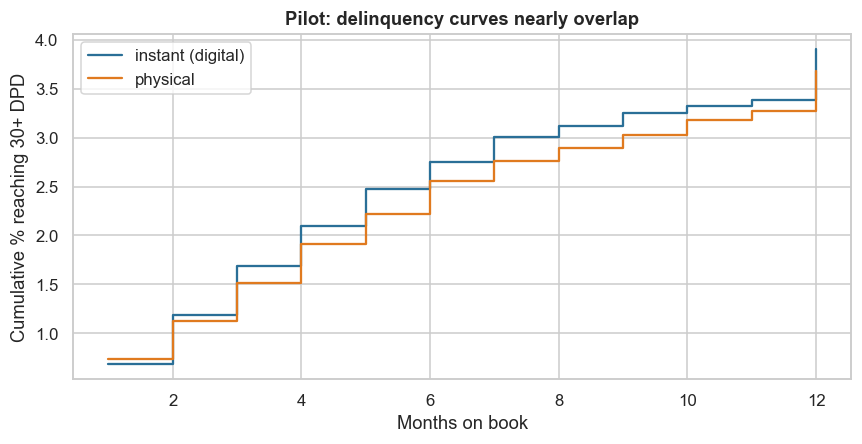

In [11]:
srm = stats.chisquare(pil.digital.value_counts().values); sb = pd.Series(smd(pil, BAL[:-1]), name="SMD")
print(f"SRM: {pil.digital.value_counts().to_dict()}, χ² p = {srm.pvalue:.3f} | max |SMD| = {sb.abs().max():.3f}")
prim = ni_test(pil, "PILOT (randomised), 30+ DPD")
x1, n1 = pil.loc[pil.digital == 1, "dpd90_12m"].sum(), (pil.digital == 1).sum(); x0, n0 = pil.loc[pil.digital == 0, "dpd90_12m"].sum(), (pil.digital == 0).sum()
lo9, hi9 = confint_proportions_2indep(x1, n1, x0, n0, method="newcomb")
lr = survdiff(pil.time, pil.dpd30_12m, pil.digital)
cox = PHReg.from_formula("time ~ digital + s_ability + s_bureau + s_behav + s_social + l_amt", status="dpd30_12m", data=pil, ties="efron").fit()
hr, hr_lo, hr_hi = np.exp(cox.params[0]), np.exp(cox.conf_int()[0, 0]), np.exp(cox.conf_int()[0, 1])
cox_s = PHReg.from_formula("time ~ digital + s_ability + s_bureau + s_behav + s_social + l_amt", status="dpd30_12m", data=pil[pil.month_missing == 0], ties="efron").fit()
print(pd.DataFrame([prim]).set_index("analysis").round(4).to_string())
print(f"\n90+ DPD (guardrail): digital {x1 / n1:.2%} vs physical {x0 / n0:.2%}, diff {100 * (x1 / n1 - x0 / n0):+.2f} pp (CI {lo9 * 100:+.2f} to {hi9 * 100:+.2f})")
print(f"Log-rank: χ² = {lr[0]:.2f}, p = {lr[1]:.3f} | Cox HR (digital vs physical, adjusted) = {hr:.3f} (95% CI {hr_lo:.3f}–{hr_hi:.3f}) → "
      f"{'non-inferior' if hr_hi < 1.25 else 'NOT shown non-inferior'} at HR margin 1.25 | excluding missing-month loans: HR {np.exp(cox_s.params[0]):.3f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for d_, c_, nm_ in ((1, "#2a6f97", "instant (digital)"), (0, "#e07a1f", "physical")):
    g = pil[pil.digital == d_]; sf = SurvfuncRight(g.time, g.dpd30_12m); ax.step(sf.surv_times, (1 - sf.surv_prob) * 100, where="post", color=c_, label=nm_)
ax.set_xlabel("Months on book"); ax.set_ylabel("Cumulative % reaching 30+ DPD"); ax.set_title("Pilot: delinquency curves nearly overlap"); ax.legend(); plt.tight_layout(); plt.show()

**Takeaway:** - **Randomisation worked:** 7,995 vs 8,005 (SRM p = 0.94), and all layers balanced (max |SMD| = 0.016).
- **Primary NI test passes:** 30+ DPD **3.90% (instant) vs 3.69% (physical)**, difference **+0.22 pp (95% CI −0.38 to +0.81)**. The upper bound is below the 1 pp margin (one-sided p_NI = 0.005), so instant processing is **non-inferior**.
- **The risk ratio** is 1.06 (upper bound 1.24 < 1.25 ✅).
- **Time to delinquency:** the curves overlap (log-rank p = 0.47), and the adjusted **Cox HR is 1.06 (CI 0.90–1.24)**, non-inferior at the 1.25 margin. Excluding the 11 loans with an imputed month gives the same HR (1.06).
- **Guardrail:** 90+ DPD 1.29% vs 1.31% (−0.02 pp, CI −0.38 to +0.33).
- **(f) Business meaning:** this is the documented claim, "delinquency on a par", now **proved** with a pre-set margin. Note the honest nuance: non-inferior does not mean identical. The best estimate is a slightly higher rate (+0.2 pp; truth +0.46 pp) that sits well within what the business accepted.

### 7.6 Was the pilot big enough? Power for non-inferiority

For an NI test, power depends on the **true** difference and the margin. Below is the sample size per arm for 80% and 90% power (one-sided α = 0.025, base rate 3.7%) for several true differences and margins, plus the power our 8,000-per-arm pilot had.

In [12]:
p0 = pil.loc[pil.digital == 0, "dpd30_12m"].mean(); rows = []
for m_ in (0.005, 0.01, 0.015):
    for true_d in (0.0, 0.002, 0.004):
        p1 = p0 + true_d; var = p0 * (1 - p0) + p1 * (1 - p1)
        n80 = int(np.ceil((1.96 + 0.84) ** 2 * var / (m_ - true_d) ** 2)); n90 = int(np.ceil((1.96 + 1.28) ** 2 * var / (m_ - true_d) ** 2))
        pw = stats.norm.cdf((m_ - true_d) / np.sqrt(var / 8000) - 1.96)
        rows.append((f"{m_ * 100:.1f} pp", f"{true_d * 100:+.1f} pp", n80, n90, pw))
pd.DataFrame(rows, columns=["NI margin", "true difference", "n per arm (80% power)", "n per arm (90% power)", "power with 8,000 per arm"]).set_index(["NI margin", "true difference"]).round(3)

n per arm (80% power)  n per arm (90% power)  power with 8,000 per arm
NI margin true difference                                                                        
0.5 pp    +0.0 pp                          22262                  29809                    0.3890
          +0.2 pp                          63449                  84957                    0.1670
          +0.4 pp                         585468                 783930                    0.0510
1.0 pp    +0.0 pp                           5566                   7453                    0.9190
          +0.2 pp                           8923                  11947                    0.7550
          +0.4 pp                          16263                  21776                    0.5020
1.5 pp    +0.0 pp                           2474                   3313                    0.9990
          +0.2 pp                           3379                   4525                    0.9910
          +0.4 pp                           4839                   6479                    0.9500

**Observation:** the pilot (8,000 per arm) had **≈ 92% power** if the channels were truly identical, but only **≈ 50%** if the true deterioration were +0.4 pp (the real value here is ≈ +0.46 pp). So it was somewhat lucky to pass. To be 80% sure with a +0.4 pp true difference needs **≈ 16,000 per arm**. A tighter margin is far more expensive: 0.5 pp needs 22,000–585,000 per arm depending on the true difference. **Business meaning:** size NI pilots for a plausible small deterioration, not for "no difference", or a genuinely acceptable channel may fail the test by chance.

## 8. ML Section — brief

The documented framework is a layered **score**, not a black box. We check whether a gradient-boosting model on the raw layer inputs beats the combined linear P27-style score (out-of-sample on the pilot loans, trained on the observational loans). If not, the transparent layered score is preferable for credit committees.

In [13]:
RAWF = ["salary_credit_monthly", "salaried_account", "avg_balance_6m", "bureau_score", "card_utilisation", "past_dpd_events_24m", "relationship_years", "digital_engagement_score", "loan_amount"]
gb = HGB(max_iter=300, learning_rate=0.06, random_state=SEED).fit(obs[RAWF], obs.dpd30_12m)
print(f"Pilot loans: AUC combined P27-style score {roc_auc_score(pil.dpd30_12m, -pil.p27_score):.4f} vs gradient boosting {roc_auc_score(pil.dpd30_12m, gb.predict_proba(pil[RAWF])[:, 1]):.4f} "
      f"(note: pilot borrowers are all eligible, so scores are range-restricted)")

Pilot loans: AUC combined P27-style score 0.5665 vs gradient boosting 0.5757 (note: pilot borrowers are all eligible, so scores are range-restricted)


**Observation:** on pilot loans, the combined P27-style score (AUC 0.567) and gradient boosting on the raw layer inputs (0.576) perform about the same. Both are low because all pilot borrowers are already in the eligible top third (range restriction). **A black-box model adds nothing material here**, so the transparent layered score is the better choice for a credit committee: each layer can be explained, monitored and challenged.

## 9. Business Translation — is "same delinquency, 10 seconds" worth it?

**Assumptions (D-17-07):**
- Physical processing costs ₹2,500 per loan (branch staff, documents, verification); instant costs ₹150.
- Loss on a 30+ DPD loan ≈ 35% of the amount (some cure, some roll to write-off).
- Average ticket from the data.

The **extra credit loss** uses the pilot's difference: point estimate and upper CI bound, plus the full 1 pp margin as the worst case the committee accepted. The saving is compared on the documented scale: about **₹2,000 crore a month** of instant disbursals.

In [14]:
avg_amt = pil.loan_amount.mean(); MONTHLY = 2000e7; n_loans = MONTHLY / avg_amt; LOSS_RATE = 0.35
op_saving = n_loans * (2500 - 150)
scen = {"pilot point estimate": prim["diff_pp"] / 100, "pilot upper 95% bound": prim["ci_high_pp"] / 100, "NI margin (worst accepted)": MARGIN, "truth (hidden model)": true_rr[1] * 0 + (true_rr[1] - true_rr[0])}
rows = [(k, d * 100, n_loans * d * avg_amt * LOSS_RATE / 1e7, op_saving / 1e7, (op_saving - n_loans * d * avg_amt * LOSS_RATE) / 1e7) for k, d in scen.items()]
be = op_saving / (n_loans * avg_amt * LOSS_RATE) * 100
print(f"Average ticket ₹{avg_amt:,.0f} → ≈ {n_loans:,.0f} instant loans a month | break-even extra delinquency = {be:.2f} pp")
pd.DataFrame(rows, columns=["scenario", "extra 30+ DPD (pp)", "extra credit loss ₹ crore/month", "processing saving ₹ crore/month", "net ₹ crore/month"]).set_index("scenario").round(2)

Average ticket ₹698,307 → ≈ 28,641 instant loans a month | break-even extra delinquency = 0.96 pp


,extra 30+ DPD (pp),extra credit loss ₹ crore/month,processing saving ₹ crore/month,net ₹ crore/month
scenario,,,,
pilot point estimate,0.2200,1.5200,6.7300,5.2100
pilot upper 95% bound,0.8100,5.6800,6.7300,1.0500
NI margin (worst accepted),1.0000,7.0000,6.7300,-0.2700
truth (hidden model),0.4600,3.2100,6.7300,3.5200


**Takeaway (business reading):** at the documented scale (≈ **₹2,000 crore of instant loans a month**, ≈ 28,600 loans at a ₹7 lakh average ticket in this simulation):
- **Processing saving** (₹2,500 → ₹150 per loan): ≈ **₹6.7 crore/month**, before counting the faster turnaround (10 seconds vs ~2–3 days), which also raises take-up.
- **Extra credit loss (35% loss on extra 30+ DPD loans):**
  - Pilot point estimate (+0.22 pp): ₹1.5 crore → **net +₹5.2 crore/month**.
  - Pilot upper bound (+0.81 pp): ₹5.7 crore → net +₹1.05 crore/month.
  - At the full 1 pp margin: ₹7.0 crore → net −₹0.27 crore/month.
  - Hidden truth (+0.46 pp): net +₹3.5 crore/month.
- **Break-even deterioration = 0.96 pp:** the 1 pp margin sits almost exactly at break-even, so the committee's margin choice is economically consistent.
- All figures rest on the stated cost and loss assumptions.

## 10. Recommendation and Decision

**Decision against the pre-registered rule:**
- **Primary, pilot ✅ non-inferior** (+0.22 pp, upper bound 0.81 < 1.0 pp).
- **Secondary ✅:** RR upper bound 1.24 < 1.25; HR upper bound 1.24 < 1.25.
- **Guardrail ✅:** 90+ DPD equal.
- **Observational analyses:** inconclusive or misleading, and not used for the decision.
- **Layers:** bureau ✅ and behaviour ✅ add information; ability ❌ (after loan size); social ≈ ❌ (Holm p = 0.07).

**I recommend:**
1. **Continue 10-second loans for eligible customers.** The evidence now meets a proper NI standard, not just "looked similar".
2. **Make the randomised NI pilot the gate for every eligibility expansion** (e.g., moving from the top third to the top 40%): a pre-registered 1 pp margin (≈ break-even), ≥ 16,000 loans per arm to be robust to a +0.4 pp true deterioration, and 12- and 24-month reads.
3. **Never use raw or "adjusted" channel comparisons as proof:** branch underwriting uses unrecorded information (E-value ≈ 3).
4. **Simplify the score:** drop or re-justify the "social" layer (privacy, fairness, little value). Keep the bureau and behaviour layers.
5. **Monitor monthly:** 30+ DPD by channel and vintage, with a CUSUM alarm if instant-loan delinquency drifts above physical by more than 0.5 pp.

**KPIs:** 12- and 24-month 30+ and 90+ DPD by channel (pilot-controlled); processing cost per loan; TAT; take-up of pre-approved offers; complaints/mis-selling flags on instant loans.

## 11. Risks, Limitations and Next Steps

- **Synthetic effects:** the hidden channel effect (+0.12 log-odds) and the branch screening were assumed. The *method* (pre-set margin, randomised pilot, one-sided CI) is what transfers.
- **Margin choice:** the 1 pp margin must be agreed *before* looking at data and justified economically (§9 gives the break-even). Post-hoc margins are not credible.
- **12 months is short for PL:** losses on 3–5-year loans emerge later. Re-test NI on 24-month 90+ DPD.
- **Who is "eligible" will change:** if the bank widens eligibility beyond the top third, the pilot result does not automatically transfer. Run a new NI pilot for each expansion band.
- **"Social" scores:** internet-usage data raise consent and fairness concerns (DPDP Act; RBI DLG on data use). §7.1 shows how little it adds here, so it is a good candidate to drop.
- **Ethics of the pilot:** randomising processing channel is low-risk when both channels apply the same credit policy. Customers must see the same terms (KFS) in both arms.

## 12. Appendix

| Quantity | Formula |
|---|---|
| Non-inferiority (difference) | H0: p_d − p_p ≥ δ; reject if upper 95% CI < δ (one-sided α = 0.025) |
| Farrington–Manning-style z | z = (p̂_d − p̂_p − δ) / SE; p = Φ(z) |
| Newcombe CI | hybrid Wilson-score interval for p₁ − p₂ |
| ATT weights | digital: 1; physical: e/(1 − e), e = P(digital ∣ X) |
| SMD | (mean_d − mean_p) / √((s²_d + s²_p)/2) |
| E-value | RR + √(RR·(RR − 1)) |
| Cox model | h(t ∣ x) = h₀(t)·exp(β·digital + γ·x) |
| NI sample size | n = (z₁₋α + z₁₋β)² (p₁q₁ + p₀q₀) / (δ − Δ)² |

| Term | Meaning |
|---|---|
| Non-inferiority | Showing a new option is not worse than the standard by more than a pre-agreed margin |
| Margin (δ) | The largest deterioration the business will accept |
| Pre-approved / instant loan | A loan offered to existing customers from data the bank already holds |
| Confounding | A difference between groups that is not caused by the channel |
| IPW | Inverse-probability weighting: reweighting one group to resemble the other |
| E-value | Strength of hidden confounding needed to explain away a result |
| DPD | Days past due |